# Baltimore 311 Resolution Time: Data Cleaning (Part 1)

**Team Chingu:** Manikrishneshwar Sasidhar, Yeo Eun Yoon

This notebook covers the first cleaning pass only:

1. Load the 2024 and 2025 Open Baltimore 311 files
2. First look and visualization of the raw data
3. Fix data types
4. Remove invalid records and requests that aren't service work
5. Handle missing values
6. Calculate the target variable, `resolution_days`
7. Basic date features
8. Cleaning summary and save

**Scope:** all agencies, excluding 311 call-center information requests and city-generated (proactive / system) requests.

Not covered here: full EDA, feature engineering, ACS census data, modeling.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

YEARS = [2024, 2025]
DATE_FORMAT = "%m/%d/%Y %I:%M:%S %p"

# 311 call center: questions answered on the phone, not service work
CALL_CENTER_AGENCY = "ECC"

MAX_RESOLUTION_DAYS = 365

# Generous bounding box around Baltimore City
LAT_RANGE = (39.19, 39.38)
LON_RANGE = (-76.72, -76.52)

In [2]:
cleaning_log = []


def log_step(step, frame):
    cleaning_log.append({"step": step, "rows": len(frame)})
    print(f"{step:<50} {len(frame):>10,} rows")


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load raw data

Source: Open Baltimore, *311 Customer Service Requests 2024* and *2025* (CSV export), saved in `data/raw/` as
`311_Customer_Service_Requests_2024_*.csv` and `311_Customer_Service_Requests_2025_*.csv`.

Everything is read as text first so that type conversion is explicit and nothing is silently mis-parsed.
Columns not needed for this project are skipped:

| Dropped | Reason |
|---|---|
| `RowID`, `SRRecordID`, `ESRI_OID`, `HashedRecord`, `NeedsSync`, `IsDeleted` | Internal system fields (`IsDeleted` is 0 for every row) |
| `GeoLocation`, `x`, `y` | Duplicates of `Latitude` / `Longitude` |
| `StatusDate`, `LastActivity`, `LastActivityDate`, `Outcome` | Recorded *after* the request is handled, so they would leak the answer |
| `Address`, `PolicePost` | Too granular for now; location is covered by coordinates / neighborhood |

In [3]:
KEEP_COLS = [
    "ServiceRequestNum", "SRType", "MethodReceived", "SRStatus",
    "CreatedDate", "DueDate", "CloseDate", "Agency",
    "ZipCode", "Neighborhood", "CouncilDistrict", "PoliceDistrict",
    "Latitude", "Longitude",
]

frames = []
for year in YEARS:
    (path,) = RAW_DIR.glob(f"311_Customer_Service_Requests_{year}_*.csv")
    frame = pd.read_csv(
        path,
        usecols=KEEP_COLS,
        dtype=str,
        encoding_errors="replace",
    )
    frame["source_year"] = year
    frames.append(frame)

raw = pd.concat(frames, ignore_index=True)[KEEP_COLS + ["source_year"]]
log_step("Raw data (2024 + 2025)", raw)
raw.head()

Raw data (2024 + 2025)                              2,013,191 rows


,ServiceRequestNum,SRType,MethodReceived,SRStatus,CreatedDate,DueDate,CloseDate,Agency,ZipCode,Neighborhood,CouncilDistrict,PoliceDistrict,Latitude,Longitude,source_year
0,24-00000007,TRS-48 Hour Parking/Abandoned Vehicle,API,Closed,1/1/2024 12:11:10 AM,1/8/2024 12:11:09 AM,1/5/2024 3:58:07 PM,Transportation ...,21215,Woodmere,6,Northwestern,39.343041765917619,-76.686078294484034,2024
1,24-00000008,SW-Graffiti Removal,API,Closed,1/1/2024 12:12:21 AM,1/15/2024 12:12:21 AM,1/3/2024 2:45:00 PM,Solid Waste ...,21217,Penn North,7,Western,39.310466431895868,-76.646214120936790,2024
2,24-00000014,TRS-48 Hour Parking/Abandoned Vehicle,API,Closed,1/1/2024 12:20:16 AM,1/8/2024 12:20:16 AM,1/9/2024 10:13:43 AM,Transportation ...,21215,Woodmere,6,Northwestern,39.342901200556817,-76.685887412517729,2024
3,24-00000023,TRS-48 Hour Parking/Abandoned Vehicle,API,Closed,1/1/2024 12:31:24 AM,1/8/2024 12:31:23 AM,1/9/2024 10:13:49 AM,Transportation ...,21215,Woodmere,6,Northwestern,39.342097765371840,-76.684504883911828,2024
4,24-00000001,ECC-Information Request,Phone,Closed,1/1/2024 12:01:11 AM,12/31/2023 7:01:11 PM,1/1/2024 12:02:00 AM,ECC ...,NaN,NaN,NaN,NaN,NaN,NaN,2024


**Standardize request status.** The raw `SRStatus` packs two things into one label (where the request stands, and
whether it was a duplicate or transfer), and the duplicate tag is spelled several different ways. We replace it
right away with labels that each mean something different:

| Status | Meaning |
|---|---|
| `Closed (Standard)` | Closed by the agency through the normal process |
| `Closed (Transferred)` | Closed because it was handed to another agency |
| `Closed (Duplicate)` | Same problem already reported; closed and linked to the original |
| `Closed (Duplicate, no close date)` | Closed as a duplicate, but no `CloseDate` was ever recorded |
| `Not closed (New)` | Logged, not yet picked up by the agency |
| `Not closed (Open)` | Agency is working on it |
| `Not closed (Pending)` | Waiting on something (inspection, another party) |
| `Not closed (On hold)` | Paused |
| `Not closed (Duplicate)` | Tagged as a duplicate before the original was finished |

In [4]:
raw_status = raw["SRStatus"].str.strip()
base = raw_status.str.extract(r"^([A-Za-z]+)", expand=False)
is_dup = raw_status.str.contains("Duplicate", case=False)
is_transfer = raw_status.str.contains("Transferred", case=False)
is_closed = base.eq("Closed")
has_close_date = raw["CloseDate"].notna()
n_raw_labels = raw_status.nunique()
not_closed_stage = "Not closed (" + base.replace({"Hold": "On hold"}) + ")"

raw["SRStatus"] = np.select(
    [
        is_closed & is_transfer,
        is_closed & is_dup & has_close_date,
        is_closed & is_dup,
        is_closed,
        is_dup,
    ],
    [
        "Closed (Transferred)",
        "Closed (Duplicate)",
        "Closed (Duplicate, no close date)",
        "Closed (Standard)",
        "Not closed (Duplicate)",
    ],
    default=not_closed_stage.to_numpy(),
)

print(f"{n_raw_labels} raw status labels -> {raw['SRStatus'].nunique()} standardized labels")
raw["SRStatus"].value_counts().rename("requests").to_frame()

12 raw status labels -> 9 standardized labels


,requests
SRStatus,
Closed (Standard),1871826
Closed (Transferred),48446
Closed (Duplicate),47677
Not closed (New),26017
Not closed (Open),15964
Not closed (Duplicate),2285
Not closed (Pending),415
"Closed (Duplicate, no close date)",372
Not closed (On hold),189


## 2. First look at the raw data

In [5]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "n_missing": raw.isna().sum(),
    "pct_missing": raw.isna().mean().mul(100).round(2),
    "example": raw.iloc[0],
})
overview

,dtype,n_unique,n_missing,pct_missing,example
ServiceRequestNum,str,2013191,0,0.00,24-00000007
SRType,str,319,0,0.00,TRS-48 Hour Parking/Abandoned Vehicle
MethodReceived,str,11,0,0.00,API
SRStatus,str,9,0,0.00,Closed (Standard)
CreatedDate,str,1908284,0,0.00,1/1/2024 12:11:10 AM
DueDate,str,1898828,32,0.00,1/8/2024 12:11:09 AM
CloseDate,str,1570223,44221,2.20,1/5/2024 3:58:07 PM
Agency,str,16,76009,3.78,Transportation ...
ZipCode,str,69,579439,28.78,21215
Neighborhood,str,279,609158,30.26,Woodmere


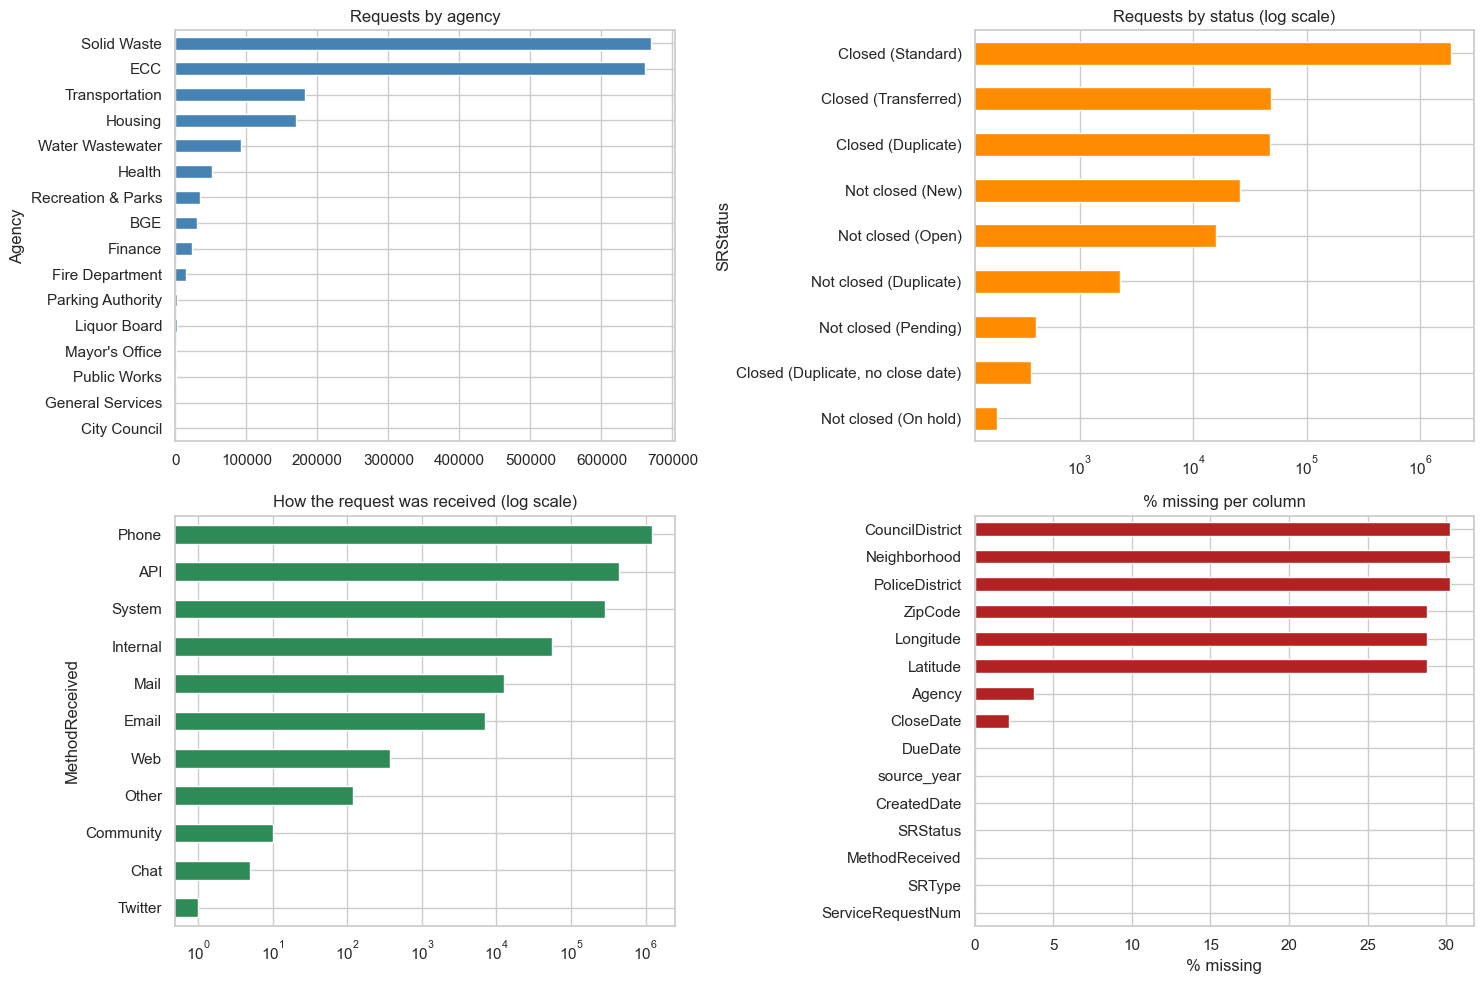

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

raw["Agency"].str.strip().value_counts().plot.barh(ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Requests by agency")
axes[0, 0].invert_yaxis()

raw["SRStatus"].value_counts().plot.barh(ax=axes[0, 1], color="darkorange", logx=True)
axes[0, 1].set_title("Requests by status (log scale)")
axes[0, 1].invert_yaxis()

raw["MethodReceived"].value_counts().plot.barh(ax=axes[1, 0], color="seagreen", logx=True)
axes[1, 0].set_title("How the request was received (log scale)")
axes[1, 0].invert_yaxis()

raw.isna().mean().mul(100).sort_values().plot.barh(ax=axes[1, 1], color="firebrick")
axes[1, 1].set_title("% missing per column")
axes[1, 1].set_xlabel("% missing")

savefig("01_raw_overview")

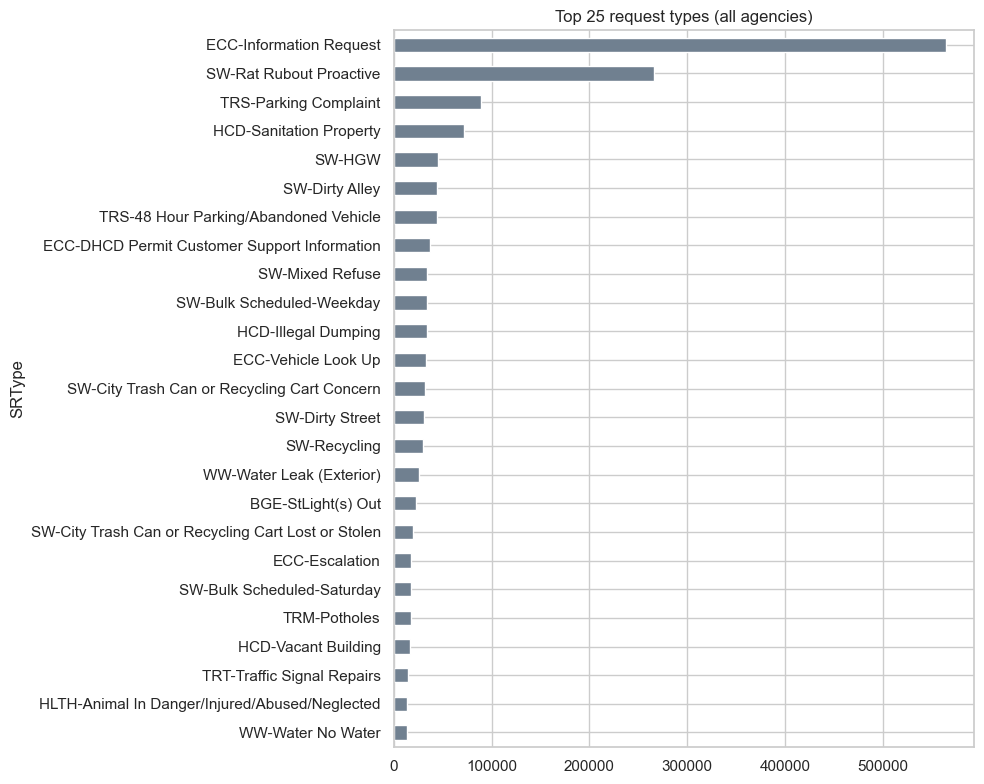

In [7]:
fig, ax = plt.subplots(figsize=(10, 8))
raw["SRType"].value_counts().head(25).plot.barh(ax=ax, color="slategray")
ax.set_title("Top 25 request types (all agencies)")
ax.invert_yaxis()
savefig("02_top_request_types_raw")

**What the raw data tells us**

- Every column is text, including dates and coordinates, so types have to be fixed before anything else.
- `Agency` values are padded with trailing spaces (e.g. `"Transportation                                    "`).
- Duplicates and transfers are recorded as a *status*, not as separate records (standardized above).
- The biggest request type, `ECC-Information Request`, is a call-center information call, not a service job.
  `SW-Rat Rubout Proactive` is generated by the city itself rather than by a resident.
- Missing data is concentrated in `CloseDate` (open requests) and the location columns.

## 3. Fix data types

In [8]:
df = raw.copy()
dtypes_before = df.dtypes.astype(str)

text_cols = [c for c in df.columns if c != "source_year"]
for col in text_cols:
    df[col] = df[col].str.strip().replace("", np.nan)

DATE_COLS = ["CreatedDate", "DueDate", "CloseDate"]
for col in DATE_COLS:
    parsed = pd.to_datetime(df[col], format=DATE_FORMAT, errors="coerce")
    n_failed = parsed.isna().sum() - df[col].isna().sum()
    print(f"{col:<12} unparseable values: {n_failed}")
    df[col] = parsed

df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")
df["CouncilDistrict"] = pd.to_numeric(df["CouncilDistrict"], errors="coerce").astype("Int64")

CreatedDate  unparseable values: 0


DueDate      unparseable values: 0


CloseDate    unparseable values: 0


**Status flags.** From the standardized status, derive a base status (`status_clean`: `Closed` or `Not closed`)
and two flags, `is_duplicate` and `is_transferred`, used for filtering in section 4.

In [9]:
df["is_duplicate"] = df["SRStatus"].str.contains("Duplicate")
df["is_transferred"] = df["SRStatus"].str.contains("Transferred")
df["status_clean"] = df["SRStatus"].str.extract(r"^(Closed|Not closed)", expand=False)

pd.crosstab(df["SRStatus"], df["status_clean"])

status_clean,Closed,Not closed
SRStatus,,
Closed (Duplicate),47677,0
"Closed (Duplicate, no close date)",372,0
Closed (Standard),1871826,0
Closed (Transferred),48446,0
Not closed (Duplicate),0,2285
Not closed (New),0,26017
Not closed (On hold),0,189
Not closed (Open),0,15964
Not closed (Pending),0,415


In [10]:
CAT_COLS = [
    "SRType", "MethodReceived", "SRStatus", "status_clean", "Agency",
    "ZipCode", "Neighborhood", "PoliceDistrict",
]
df[CAT_COLS] = df[CAT_COLS].astype("category")

pd.DataFrame({"before": dtypes_before, "after": df.dtypes.astype(str)}).fillna("(new)")

,before,after
Agency,str,category
CloseDate,str,datetime64[us]
CouncilDistrict,str,Int64
CreatedDate,str,datetime64[us]
DueDate,str,datetime64[us]
Latitude,str,float64
Longitude,str,float64
MethodReceived,str,category
Neighborhood,str,category
PoliceDistrict,str,category


`ZipCode` is kept as a category rather than a number: it is a label, and doing arithmetic on it would be meaningless.
`CouncilDistrict` uses pandas' nullable `Int64` so missing values don't turn it into a float.

With real dates in place, we can plot request volume over time:

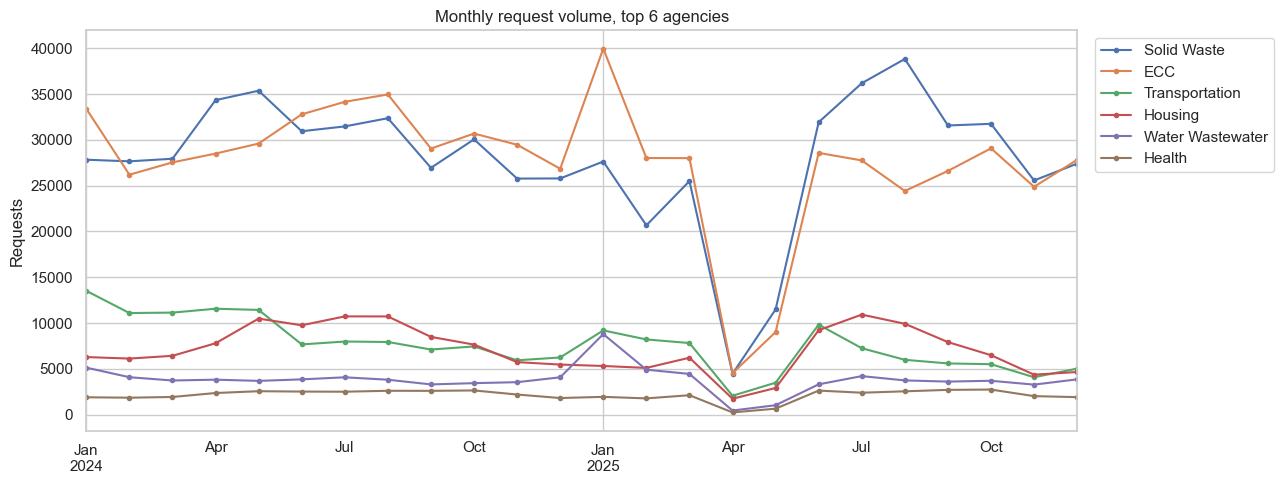

In [11]:
monthly = (
    df.assign(month=df["CreatedDate"].dt.to_period("M").dt.to_timestamp())
    .groupby(["month", "Agency"], observed=True)
    .size()
    .unstack()
)
top_agencies = monthly.sum().nlargest(6).index

fig, ax = plt.subplots(figsize=(13, 5))
monthly[top_agencies].plot(ax=ax, marker="o", markersize=3)
ax.set_title("Monthly request volume, top 6 agencies")
ax.set_xlabel("")
ax.set_ylabel("Requests")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("03_monthly_volume_by_agency")

## 4. Remove invalid records and requests that aren't service work

In [12]:
n_exact_dupes = df.duplicated().sum()
n_id_dupes = df["ServiceRequestNum"].duplicated().sum()
print(f"Exact duplicate rows:            {n_exact_dupes:,}")
print(f"Duplicate ServiceRequestNum:     {n_id_dupes:,}")
print(f"Flagged duplicate (via status):  {df['is_duplicate'].sum():,}")
print(f"Transferred to another agency:   {df['is_transferred'].sum():,}")

df = df.drop_duplicates()
df = df.drop_duplicates(subset="ServiceRequestNum")
log_step("Drop exact / ID duplicates", df)

df = df[~df["is_duplicate"]]
log_step("Drop requests flagged as duplicates", df)

df = df[~df["is_transferred"]]
log_step("Drop transferred requests", df)

Exact duplicate rows:            0
Duplicate ServiceRequestNum:     0
Flagged duplicate (via status):  50,334
Transferred to another agency:   48,446


Drop exact / ID duplicates                          2,013,191 rows


Drop requests flagged as duplicates                 1,962,857 rows


Drop transferred requests                           1,914,411 rows


**311 call-center requests.** Requests filed under the `ECC` agency are mostly questions answered on the phone
(information requests, vehicle look-ups, permit information). They're closed within seconds of being logged, so
their "resolution time" is just the length of the call, not service work.

- `ECC-Escalation` requests filed under *other* agencies are real follow-ups and are kept.
- Requests with no agency listed (mostly parking complaints) are kept; their agency becomes `"Unknown"` in section 5.

In [13]:
is_call_center = df["Agency"].eq(CALL_CENTER_AGENCY)
tmp_days = (df["CloseDate"] - df["CreatedDate"]).dt.total_seconds() / 86400

(
    tmp_days.groupby(is_call_center.rename("call center (ECC)"))
    .describe(percentiles=[0.25, 0.5, 0.75])
    .rename(columns={"50%": "median"})
)

,count,mean,std,min,25%,median,75%,max
call center (ECC),,,,,,,,
False,1238791.0,12.965341,40.061705,-416.108461,0.000891,1.013252,8.192500,715.479884
True,634032.0,0.024076,1.684386,-0.001887,0.000012,0.000012,0.000405,457.503044


In [14]:
df = df[~is_call_center].copy()
df["Agency"] = df["Agency"].cat.remove_unused_categories()
log_step("Drop 311 call-center (ECC) requests", df)

Drop 311 call-center (ECC) requests                 1,259,614 rows


**City-initiated (proactive / system) requests.** Some requests are opened by the city itself, e.g. scheduled rat
baiting (`SW-Rat Rubout Proactive`), and are marked closed within seconds. They don't reflect how long it takes
to respond to a resident, so they would distort the target.

In [15]:
is_proactive = (
    df["SRType"].str.contains("Proactive", case=False, na=False)
    | df["MethodReceived"].eq("System")
)
tmp_days = (df["CloseDate"] - df["CreatedDate"]).dt.total_seconds() / 86400

(
    tmp_days.groupby(is_proactive.rename("proactive / system"))
    .describe(percentiles=[0.25, 0.5, 0.75])
    .rename(columns={"50%": "median"})
)

,count,mean,std,min,25%,median,75%,max
proactive / system,,,,,,,,
False,936778.0,16.705315,44.355108,-416.108461,0.564479,3.029016,12.799893,715.479884
True,302013.0,1.364765,17.400807,-19.000347,0.000058,0.000069,0.000127,623.160833


In [16]:
df = df[~is_proactive].copy()
log_step("Drop proactive / system-generated requests", df)

Drop proactive / system-generated requests            957,169 rows


## 5. Handle missing values

In [17]:
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean().mul(100).round(2),
}).query("n_missing > 0").sort_values("n_missing", ascending=False)
missing

,n_missing,pct_missing
Agency,67721,7.08
CouncilDistrict,28556,2.98
Neighborhood,28545,2.98
PoliceDistrict,28476,2.98
CloseDate,20391,2.13
ZipCode,4705,0.49
Latitude,4353,0.45
Longitude,4353,0.45
DueDate,22,0.00


In [18]:
pd.crosstab(df["status_clean"], df["CloseDate"].isna().rename("CloseDate missing"))

CloseDate missing,False,True
status_clean,,
Closed,936700,0
Not closed,78,20391


In [19]:
geo_cols = ["Neighborhood", "CouncilDistrict", "PoliceDistrict"]
geo_missing_pattern = df[geo_cols].isna().value_counts().rename("rows")
geo_missing_pattern

Neighborhood  CouncilDistrict  PoliceDistrict
False         False            False             928295
True          True             True               28252
False         True             False                163
True          False            False                133
False         False            True                 127
True          True             False                102
              False            True                  58
False         True             True                  39
Name: rows, dtype: int64

**Decisions**

| Column(s) | What's going on | Action |
|---|---|---|
| `CloseDate` | Missing only for requests that are `Not closed` (new, open, pending, on hold) | Drop these rows. There's no target to learn from, and they're a tiny share of the data (the export was pulled in Sep 2026, so even late-2025 requests had 9+ months to close). |
| `Closed` with no `CloseDate` | Would be a data error | Drop (if any) |
| `Agency` | Missing almost entirely for parking complaints | Fill with `"Unknown"` so these requests stay in the data |
| `Neighborhood`, `CouncilDistrict`, `PoliceDistrict` | Usually missing together (the address didn't match a boundary) | Fill with `"Unknown"` rather than drop, so we don't bias against certain areas |
| `ZipCode` | Missing where there's no address | Fill with `"Unknown"` |
| `Latitude` / `Longitude` | Missing for some request types with no street address, and some points fall outside the city limits (these also have an unknown neighborhood) | Set out-of-city points to NaN and keep a `has_valid_coords` flag |
| `DueDate` | Few missing | Leave as NaN for now; it will be used as a feature later |

In [20]:
df = df[df["status_clean"].eq("Closed")]
log_step("Keep closed requests only", df)

df = df[df["CloseDate"].notna()].copy()
log_step("Drop closed requests with no CloseDate", df)

for col in ["Agency", "Neighborhood", "PoliceDistrict", "ZipCode"]:
    df[col] = df[col].cat.add_categories("Unknown").fillna("Unknown")
df["CouncilDistrict"] = df["CouncilDistrict"].astype("string").fillna("Unknown").astype("category")

in_city = (
    df["Latitude"].between(*LAT_RANGE)
    & df["Longitude"].between(*LON_RANGE)
)
print(f"Coordinates missing or outside Baltimore: {(~in_city).sum():,}")
df.loc[~in_city, ["Latitude", "Longitude"]] = np.nan
df["has_valid_coords"] = in_city

df.isna().sum().loc[lambda s: s > 0]

Keep closed requests only                             936,700 rows
Drop closed requests with no CloseDate                936,700 rows


Coordinates missing or outside Baltimore: 22,782


DueDate          7
Latitude     22782
Longitude    22782
dtype: int64

## 6. Target variable: `resolution_days`

$$\text{resolution\_days} = \frac{\text{CloseDate} - \text{CreatedDate}}{1 \text{ day}}$$

In [21]:
df["resolution_days"] = (df["CloseDate"] - df["CreatedDate"]).dt.total_seconds() / 86400

checks = pd.Series({
    "negative (closed before created)": (df["resolution_days"] < 0).sum(),
    "closed within 1 minute": df["resolution_days"].between(0, 1 / 1440).sum(),
    f"longer than {MAX_RESOLUTION_DAYS} days": (df["resolution_days"] > MAX_RESOLUTION_DAYS).sum(),
}, name="rows")
checks

negative (closed before created)     2366
closed within 1 minute              13737
longer than 365 days                 2995
Name: rows, dtype: int64

In [22]:
df = df[df["resolution_days"] >= 0]
log_step("Drop negative resolution times", df)

df = df[df["resolution_days"] <= MAX_RESOLUTION_DAYS].copy()
log_step(f"Drop resolution > {MAX_RESOLUTION_DAYS} days", df)

df["log_resolution_days"] = np.log1p(df["resolution_days"])
df["resolution_days"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

Drop negative resolution times                        934,334 rows
Drop resolution > 365 days                            931,339 rows


count    931339.000000
mean         15.325286
std          36.495578
min           0.000000
5%            0.020637
25%           0.573351
50%           3.024873
75%          12.688628
90%          41.319139
95%          65.580877
99%         211.509741
max         364.981435
Name: resolution_days, dtype: float64

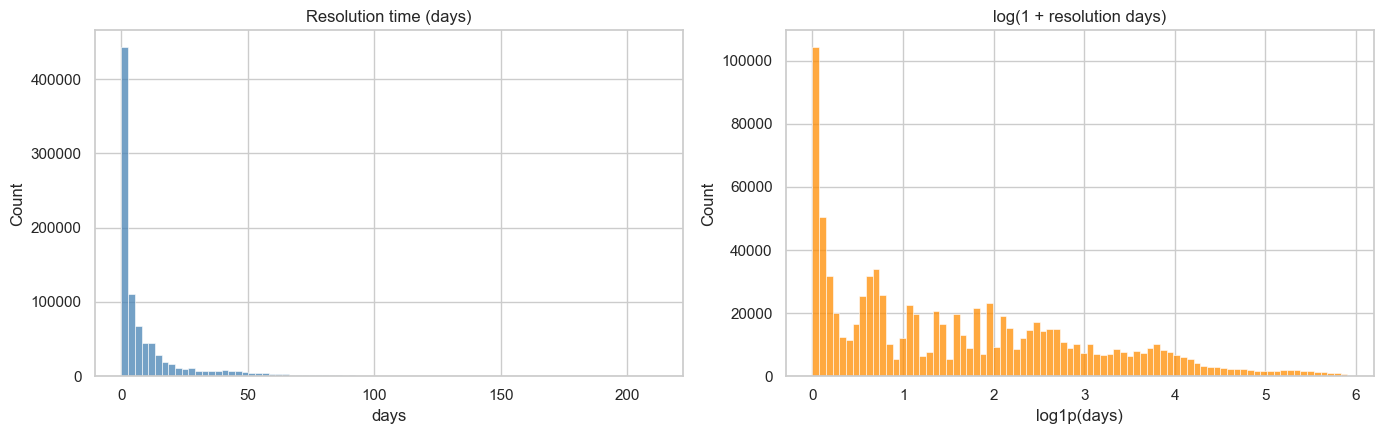

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

clip = df["resolution_days"].quantile(0.99)
sns.histplot(df.loc[df["resolution_days"] <= clip, "resolution_days"], bins=80, ax=axes[0], color="steelblue")
axes[0].set_title("Resolution time (days)")
axes[0].set_xlabel("days")

sns.histplot(df["log_resolution_days"], bins=80, ax=axes[1], color="darkorange")
axes[1].set_title("log(1 + resolution days)")
axes[1].set_xlabel("log1p(days)")

savefig("04_target_distribution")

The raw target is heavily right-skewed: most requests close within days, and a long tail runs for months.
`log_resolution_days` is much better behaved and is likely the better modeling target. Metrics can be reported back
in days.

The left chart leaves out the slowest 1% of requests so the rest of the distribution is readable; the right chart
includes every request.

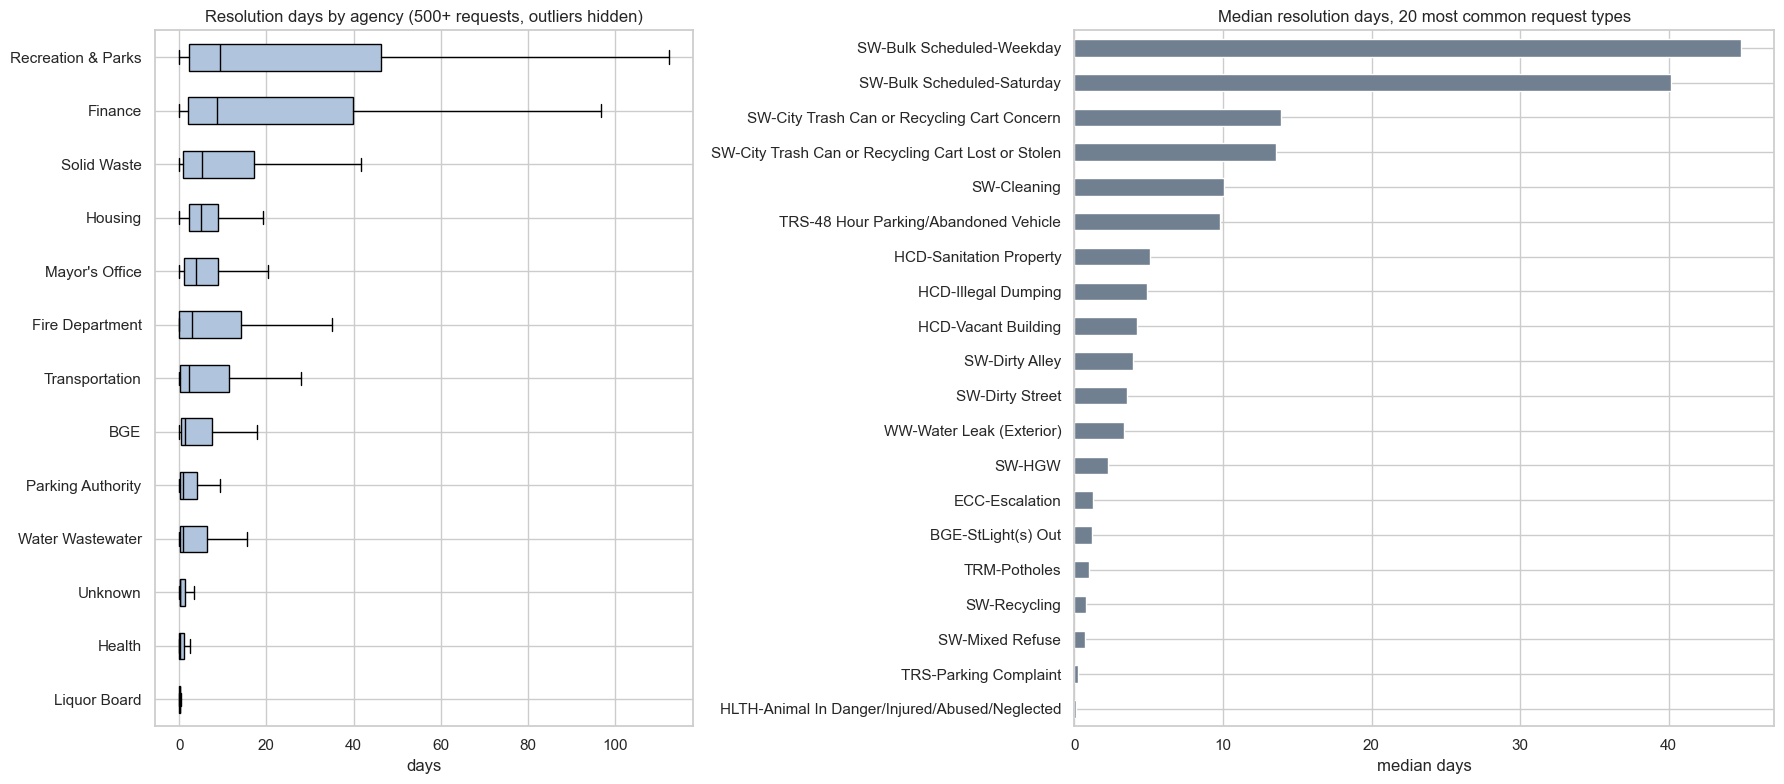

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8), gridspec_kw={"width_ratios": [1, 1.3]})

agency_counts = df["Agency"].value_counts()
agency_order = (
    df[df["Agency"].isin(agency_counts[agency_counts >= 500].index)]
    .groupby("Agency", observed=True)["resolution_days"]
    .median()
    .sort_values()
    .index
)
axes[0].boxplot(
    [df.loc[df["Agency"].eq(a), "resolution_days"] for a in agency_order],
    labels=agency_order, vert=False, showfliers=False, patch_artist=True,
    boxprops={"facecolor": "lightsteelblue"}, medianprops={"color": "black"},
)
axes[0].set_xlabel("days")
axes[0].set_title("Resolution days by agency (500+ requests, outliers hidden)")

top_types = df["SRType"].value_counts().head(20).index
type_stats = (
    df[df["SRType"].isin(top_types)]
    .groupby("SRType", observed=True)["resolution_days"]
    .agg(["median", "count"])
    .sort_values("median")
)
type_stats["median"].plot.barh(ax=axes[1], color="slategray")
axes[1].set_title("Median resolution days, 20 most common request types")
axes[1].set_xlabel("median days")
axes[1].set_ylabel("")

savefig("05_resolution_by_agency_and_type")

## 7. Basic date features

Everything here is known **at the moment the request is created**, so it's safe to use for prediction.
`sla_days` is the city's own deadline (`DueDate - CreatedDate`), which is likely to be a strong predictor.

In [25]:
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter",
           3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer",
           9: "Fall", 10: "Fall", 11: "Fall"}

created = df["CreatedDate"].dt
df["created_hour"] = created.hour
df["created_dayofweek"] = created.dayofweek
df["created_month"] = created.month
df["is_weekend"] = df["created_dayofweek"].ge(5)
df["season"] = pd.Categorical(
    df["created_month"].map(SEASONS),
    categories=["Winter", "Spring", "Summer", "Fall"],
)
df["sla_days"] = (df["DueDate"] - df["CreatedDate"]).dt.total_seconds() / 86400

df[["CreatedDate", "created_hour", "created_dayofweek", "created_month",
    "is_weekend", "season", "sla_days", "resolution_days"]].head()

,CreatedDate,created_hour,created_dayofweek,created_month,is_weekend,season,sla_days,resolution_days
0,2024-01-01 00:11:10,0,0,1,False,Winter,6.999988,4.657604
1,2024-01-01 00:12:21,0,0,1,False,Winter,14.000000,2.606007
2,2024-01-01 00:20:16,0,0,1,False,Winter,7.000000,8.412118
3,2024-01-01 00:31:24,0,0,1,False,Winter,6.999988,8.404456
6,2024-01-01 00:14:07,0,0,1,False,Winter,7.000000,8.405220


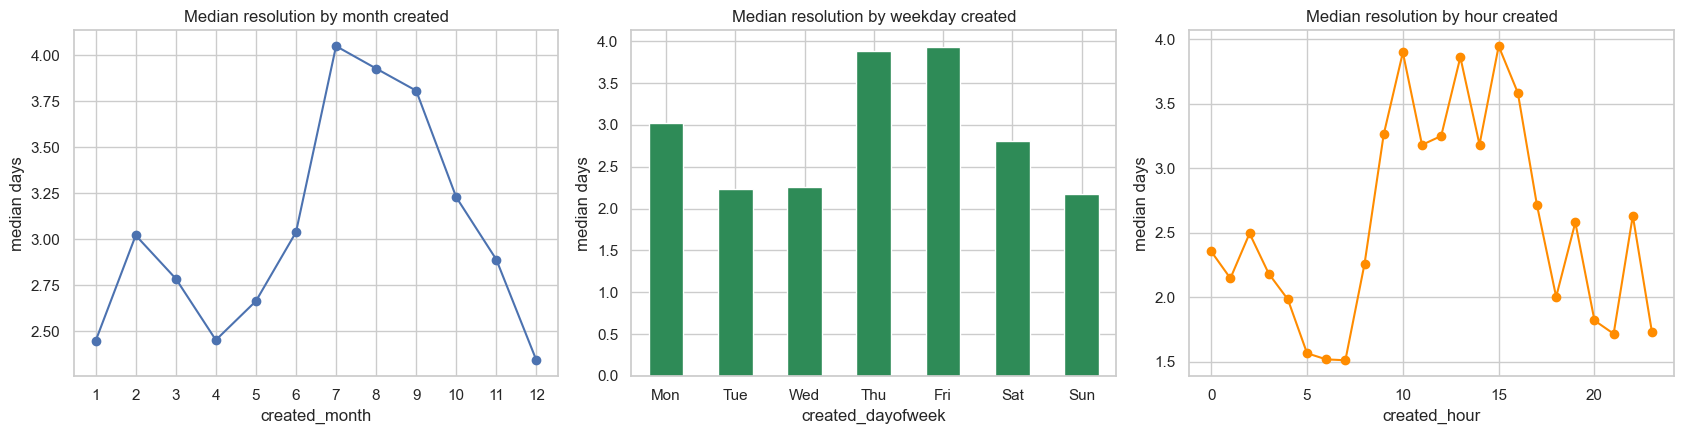

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

df.groupby("created_month")["resolution_days"].median().plot(ax=axes[0], marker="o")
axes[0].set_title("Median resolution by month created")
axes[0].set_xticks(range(1, 13))

dow_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
df.groupby("created_dayofweek")["resolution_days"].median().plot.bar(ax=axes[1], color="seagreen")
axes[1].set_xticklabels(dow_labels, rotation=0)
axes[1].set_title("Median resolution by weekday created")

df.groupby("created_hour")["resolution_days"].median().plot(ax=axes[2], marker="o", color="darkorange")
axes[2].set_title("Median resolution by hour created")

for ax in axes:
    ax.set_ylabel("median days")
savefig("06_resolution_by_time_features")

## 8. Cleaning summary and save

In [27]:
log = pd.DataFrame(cleaning_log)
log["removed"] = log["rows"].shift(1).sub(log["rows"]).fillna(0).astype(int)
log["pct_of_raw"] = log["rows"].div(log["rows"].iloc[0]).mul(100).round(1)
log

,step,rows,removed,pct_of_raw
0,Raw data (2024 + 2025),2013191,0,100.0
1,Drop exact / ID duplicates,2013191,0,100.0
2,Drop requests flagged as duplicates,1962857,50334,97.5
3,Drop transferred requests,1914411,48446,95.1
4,Drop 311 call-center (ECC) requests,1259614,654797,62.6
5,Drop proactive / system-generated requests,957169,302445,47.5
6,Keep closed requests only,936700,20469,46.5
7,Drop closed requests with no CloseDate,936700,0,46.5
8,Drop negative resolution times,934334,2366,46.4
9,Drop resolution > 365 days,931339,2995,46.3


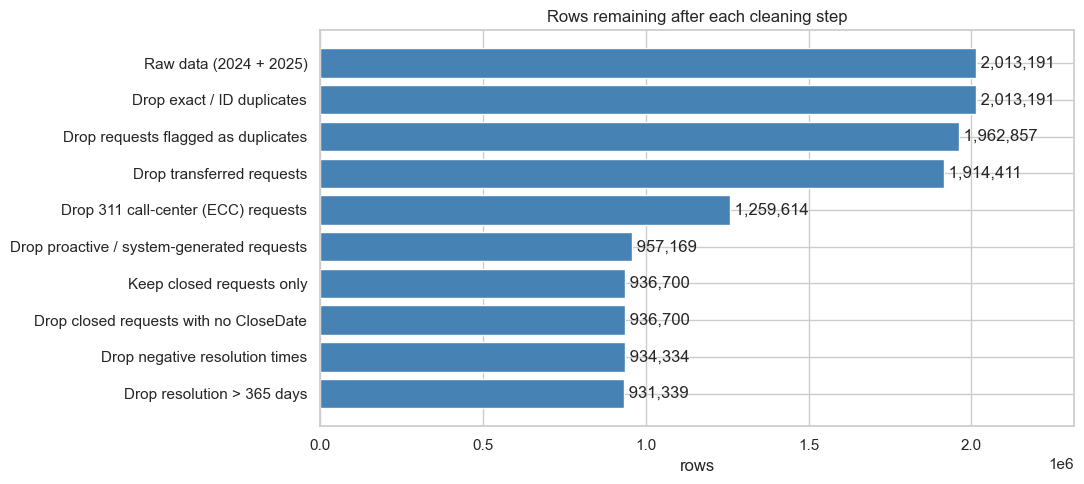

In [28]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(log["step"], log["rows"], color="steelblue")
for i, rows in enumerate(log["rows"]):
    ax.text(rows, i, f" {rows:,}", va="center")
ax.invert_yaxis()
ax.set_title("Rows remaining after each cleaning step")
ax.set_xlabel("rows")
ax.set_xlim(0, log["rows"].max() * 1.15)
savefig("07_cleaning_funnel")

In [29]:
FINAL_COLS = [
    "ServiceRequestNum", "source_year", "SRType", "Agency", "MethodReceived",
    "CreatedDate", "DueDate", "CloseDate",
    "ZipCode", "Neighborhood", "CouncilDistrict", "PoliceDistrict",
    "Latitude", "Longitude", "has_valid_coords",
    "created_hour", "created_dayofweek", "created_month", "is_weekend", "season", "sla_days",
    "resolution_days", "log_resolution_days",
]
clean = df[FINAL_COLS].reset_index(drop=True)

out_path = PROCESSED_DIR / "311_clean_2024_2025.parquet"
clean.to_parquet(out_path, index=False)
print(f"Saved {len(clean):,} rows x {clean.shape[1]} columns -> {out_path.relative_to(ROOT)}")
clean.info()

Saved 931,339 rows x 23 columns -> data\processed\311_clean_2024_2025.parquet
<class 'pandas.DataFrame'>
RangeIndex: 931339 entries, 0 to 931338
Data columns (total 23 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   ServiceRequestNum    931339 non-null  str           
 1   source_year          931339 non-null  int64         
 2   SRType               931339 non-null  category      
 3   Agency               931339 non-null  category      
 4   MethodReceived       931339 non-null  category      
 5   CreatedDate          931339 non-null  datetime64[us]
 6   DueDate              931332 non-null  datetime64[us]
 7   CloseDate            931339 non-null  datetime64[us]
 8   ZipCode              931339 non-null  category      
 9   Neighborhood         931339 non-null  category      
 10  CouncilDistrict      931339 non-null  category      
 11  PoliceDistrict       931339 non-null  category      
 12  Latit

## Next steps (not done yet)

- Check request-type categories for inconsistent or overlapping names (e.g. `SW-Rat Rubout` vs `HCD-Rodents`)
- Decide whether requests closed within seconds are real or administrative closures, especially staff-logged
  (`Internal`) requests such as `TRM-Pickup Pothole`
- Fuller EDA: resolution time by neighborhood and council district, maps
- Feature engineering: request-type grouping, agency workload (open requests at creation time), ACS neighborhood data
- Time-based train/test split (train on earlier requests, test on later ones), then median baseline and models